# Create a SpatialData object and TissUUmaps export

All functions are located in [spatialdata_helper.py](spatialdata_helper.py) and [tissuumaps_helper.py](tissuumaps_helper.py) in the 
same folder as this notebook. To change the way data is loaded, please edit these
files.
The autoreload extension will update the python kernel automatically when these python 
files are changed.

## Load modules

In [30]:
#%load_ext autoreload
#%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import os
os.add_dll_directory(r"C:\openslide\bin")  # Adjust path if needed
    
import spatialdata_helper
import tissuumaps_helper
import json

from spatialdata import SpatialData
from spatialdata.transformations import Affine, set_transformation, Identity, Sequence, Scale

from napari_spatialdata import Interactive

import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (12, 12)

## Define transformations

We define transformation from DESI to SCRINSHOT, as well as list 
of transformations applied to SCRINSHOT and DESI objects.

In [17]:
transformation_DESI_to_SCRINSHOT = Affine(
    [
     [221.0445318813514, 22.192525739874004, -15480.80390201999],
     [-2.391263297926106, 188.53377069630776, -15908.362552172099],
     [0, 0, 1]
    ],
    input_axes=("x", "y"),
    output_axes=("x", "y"),
)

scale = Scale([200,200], axes=("x", "y"))
SCRINSHOT_trans = {
    "DESI": Sequence([transformation_DESI_to_SCRINSHOT.inverse(), scale]),
    "SCRINSHOT": Identity(),
}

DESI_trans = {
    "DESI": Sequence([Identity(), scale]),
    "SCRINSHOT": transformation_DESI_to_SCRINSHOT,
}

## Create a spatial data object

### SCRINSHOT data

Add image data (DAPI from SCRINSHOT)

In [18]:
# Main input folder
input_folder = "C:/Users/matsmi/OneDrive - Karolinska Institutet/Dokument/__STUDIES/008_DESI-SCRINSHOT_dev/data"
output_folder = "C:/Users/matsmi/OneDrive - Karolinska Institutet/Dokument/__STUDIES/008_DESI-SCRINSHOT_dev/results"

os.makedirs(output_folder, exist_ok=True)

# Path to your TIFF file
tif_path = fr"{input_folder}\SCRINSHOT\13Oct_P3_lung_DESI_SCRINSHOT_SUBSET\hyb1_DAPI.tif"

# Create the spatialdata object with the image
sdata = SpatialData()

dapi_image = spatialdata_helper.load_image(
    sdata, 
    tif_path, 
    "hyb1_DAPI", 
    transformations=SCRINSHOT_trans
)
sdata

SpatialData object
└── Images
      └── 'hyb1_DAPI': DataArray[cyx] (1, 9720, 12400)
with coordinate systems:
    ▸ 'DESI', with elements:
        hyb1_DAPI (Images)
    ▸ 'SCRINSHOT', with elements:
        hyb1_DAPI (Images)

Add shapes (cell segmentation and anatomical labels)

In [ ]:
output_file = f"{output_folder}/multimodal/13Oct_P3_lung_DESI_SCRINSHOT_SUBSET/cells-large.geojson"
os.makedirs(os.path.dirname(output_file), exist_ok=True)
spatialdata_helper.roi_to_geojson(
    sdata,
    fr"{input_folder}\SCRINSHOT\13Oct_P3_lung_DESI_SCRINSHOT_SUBSET\cells-large", 
    output_file=output_file,
    class_name="cells-large",
    class_color=[255, 0, 0],
    transformations=SCRINSHOT_trans
)

output_file = f"{output_folder}/multimodal/13Oct_P3_lung_DESI_SCRINSHOT_SUBSET/anatomical_labels.geojson"
os.makedirs(os.path.dirname(output_file), exist_ok=True)
spatialdata_helper.roi_to_geojson(
    sdata,
    fr"{input_folder}\SCRINSHOT\13Oct_P3_lung_DESI_SCRINSHOT_SUBSET\anatomical_labels", 
    output_file=output_file,
    class_name="anatomical_labels",
    class_color=[0, 255, 0],
    transformations=SCRINSHOT_trans
)

sdata

SpatialData object
├── Images
│     └── 'hyb1_DAPI': DataArray[cyx] (1, 9720, 12400)
└── Shapes
      ├── 'anatomical_labels': GeoDataFrame shape: (2, 1) (2D shapes)
      └── 'cells-large': GeoDataFrame shape: (38700, 1) (2D shapes)
with coordinate systems:
    ▸ 'DESI', with elements:
        hyb1_DAPI (Images), anatomical_labels (Shapes), cells-large (Shapes)
    ▸ 'SCRINSHOT', with elements:
        hyb1_DAPI (Images), anatomical_labels (Shapes), cells-large (Shapes)

Add table (Cell types from SCRINSHOT)

In [20]:
# Load Cell types from CSV file with headers: roi	Cell.type	Number	Area	X	Y	SCGB3A2	S100A4	SPARCL1	CLDN5	FBLN1	MGP	KRT15	FOS	NAPSA	SCGB3A1	AGER	APOE	CPA3	TAGLN	RGCC
import pandas as pd
input_file = fr"{input_folder}\SCRINSHOT\13Oct_P3_lung_DESI_SCRINSHOT_SUBSET\Cell-types-gene-expression-combined-XY20.csv"

spatialdata_helper.load_table(
    sdata, 
    input_file,
    transformations=SCRINSHOT_trans
)

sdata

SpatialData object
├── Images
│     └── 'hyb1_DAPI': DataArray[cyx] (1, 9720, 12400)
├── Shapes
│     ├── 'anatomical_labels': GeoDataFrame shape: (2, 1) (2D shapes)
│     ├── 'cells': GeoDataFrame shape: (38700, 2) (2D shapes)
│     └── 'cells-large': GeoDataFrame shape: (38700, 1) (2D shapes)
└── Tables
      └── 'cell_types': AnnData (38700, 15)
with coordinate systems:
    ▸ 'DESI', with elements:
        hyb1_DAPI (Images), anatomical_labels (Shapes), cells (Shapes), cells-large (Shapes)
    ▸ 'SCRINSHOT', with elements:
        hyb1_DAPI (Images), anatomical_labels (Shapes), cells (Shapes), cells-large (Shapes)

Add points (dot coordinates from SCRINSHOT)

In [21]:
# Path to the folder containing the CSV files
input_path = fr"{input_folder}\SCRINSHOT\13Oct_P3_lung_DESI_SCRINSHOT_SUBSET\DOT-COORDINATES"

spatialdata_helper.load_points(
    sdata, 
    input_path, 
    "SCRINSHOT_DOT_COORDINATES",
    transformations=SCRINSHOT_trans
)

sdata

SpatialData object
├── Images
│     └── 'hyb1_DAPI': DataArray[cyx] (1, 9720, 12400)
├── Points
│     └── 'SCRINSHOT_DOT_COORDINATES': DataFrame with shape: (<Delayed>, 18) (2D points)
├── Shapes
│     ├── 'anatomical_labels': GeoDataFrame shape: (2, 1) (2D shapes)
│     ├── 'cells': GeoDataFrame shape: (38700, 2) (2D shapes)
│     └── 'cells-large': GeoDataFrame shape: (38700, 1) (2D shapes)
└── Tables
      └── 'cell_types': AnnData (38700, 15)
with coordinate systems:
    ▸ 'DESI', with elements:
        hyb1_DAPI (Images), SCRINSHOT_DOT_COORDINATES (Points), anatomical_labels (Shapes), cells (Shapes), cells-large (Shapes)
    ▸ 'SCRINSHOT', with elements:
        hyb1_DAPI (Images), SCRINSHOT_DOT_COORDINATES (Points), anatomical_labels (Shapes), cells (Shapes), cells-large (Shapes)

### DESI data

Add DESI data as Points and table of observations

In [31]:
input_path = fr"{input_folder}\DESI-MRM\images\13Oct_P3_lung_DESI_SCRINSHOT_SUBSET\\"

spatialdata_helper.load_DESI (
    sdata, 
    input_path, 
    element_name="DESI",
    transformations=DESI_trans
)

sdata

13Oct_P3_lung_DESI_SCRINSHOT_12-HETE _or_ 9-HETE
13Oct_P3_lung_DESI_SCRINSHOT_12-HHTrE
13Oct_P3_lung_DESI_SCRINSHOT_13-HOTrE
13Oct_P3_lung_DESI_SCRINSHOT_16-HOTrE _or_ 15_16-EpODE
13Oct_P3_lung_DESI_SCRINSHOT_6-trans-LTB4 _or_ LTB4
13Oct_P3_lung_DESI_SCRINSHOT_8-isoPGE2 _or_ PGE2 _or_ PGD2
13Oct_P3_lung_DESI_SCRINSHOT_CUDA [M-H]- _or_ CUDA [M-H]-
13Oct_P3_lung_DESI_SCRINSHOT_Hexose (gluc_fruct) [M+Cl]-
13Oct_P3_lung_DESI_SCRINSHOT_TXB2


SpatialData object, with associated Zarr store: C:\Users\matsmi\OneDrive - Karolinska Institutet\Dokument\__STUDIES\008_DESI-SCRINSHOT_dev\results\output.zarr
├── Images
│     ├── 'DESI_image': DataArray[cyx] (3, 140, 130)
│     └── 'hyb1_DAPI': DataArray[cyx] (1, 9720, 12400)
├── Points
│     └── 'SCRINSHOT_DOT_COORDINATES': DataFrame with shape: (<Delayed>, 18) (2D points)
├── Shapes
│     ├── 'DESI': GeoDataFrame shape: (18200, 2) (2D shapes)
│     ├── 'anatomical_labels': GeoDataFrame shape: (2, 1) (2D shapes)
│     ├── 'cells': GeoDataFrame shape: (38700, 2) (2D shapes)
│     └── 'cells-large': GeoDataFrame shape: (38700, 1) (2D shapes)
└── Tables
      ├── 'DESI_obs': AnnData (18200, 9)
      └── 'cell_types': AnnData (38700, 15)
with coordinate systems:
    ▸ 'DESI', with elements:
        DESI_image (Images), hyb1_DAPI (Images), SCRINSHOT_DOT_COORDINATES (Points), DESI (Shapes), anatomical_labels (Shapes), cells (Shapes), cells-large (Shapes)
    ▸ 'SCRINSHOT', with elements:
 

## Data visualization

Display the SpatialData content:

In [23]:
sdata

SpatialData object
├── Images
│     ├── 'DESI_image': DataArray[cyx] (3, 140, 130)
│     └── 'hyb1_DAPI': DataArray[cyx] (1, 9720, 12400)
├── Points
│     └── 'SCRINSHOT_DOT_COORDINATES': DataFrame with shape: (<Delayed>, 18) (2D points)
├── Shapes
│     ├── 'DESI': GeoDataFrame shape: (18200, 2) (2D shapes)
│     ├── 'anatomical_labels': GeoDataFrame shape: (2, 1) (2D shapes)
│     ├── 'cells': GeoDataFrame shape: (38700, 2) (2D shapes)
│     └── 'cells-large': GeoDataFrame shape: (38700, 1) (2D shapes)
└── Tables
      ├── 'DESI_obs': AnnData (18200, 9)
      └── 'cell_types': AnnData (38700, 15)
with coordinate systems:
    ▸ 'DESI', with elements:
        DESI_image (Images), hyb1_DAPI (Images), SCRINSHOT_DOT_COORDINATES (Points), DESI (Shapes), anatomical_labels (Shapes), cells (Shapes), cells-large (Shapes)
    ▸ 'SCRINSHOT', with elements:
        DESI_image (Images), hyb1_DAPI (Images), SCRINSHOT_DOT_COORDINATES (Points), DESI (Shapes), anatomical_labels (Shapes), cells (Shapes

Plot images and cell types in both coordinate systems:

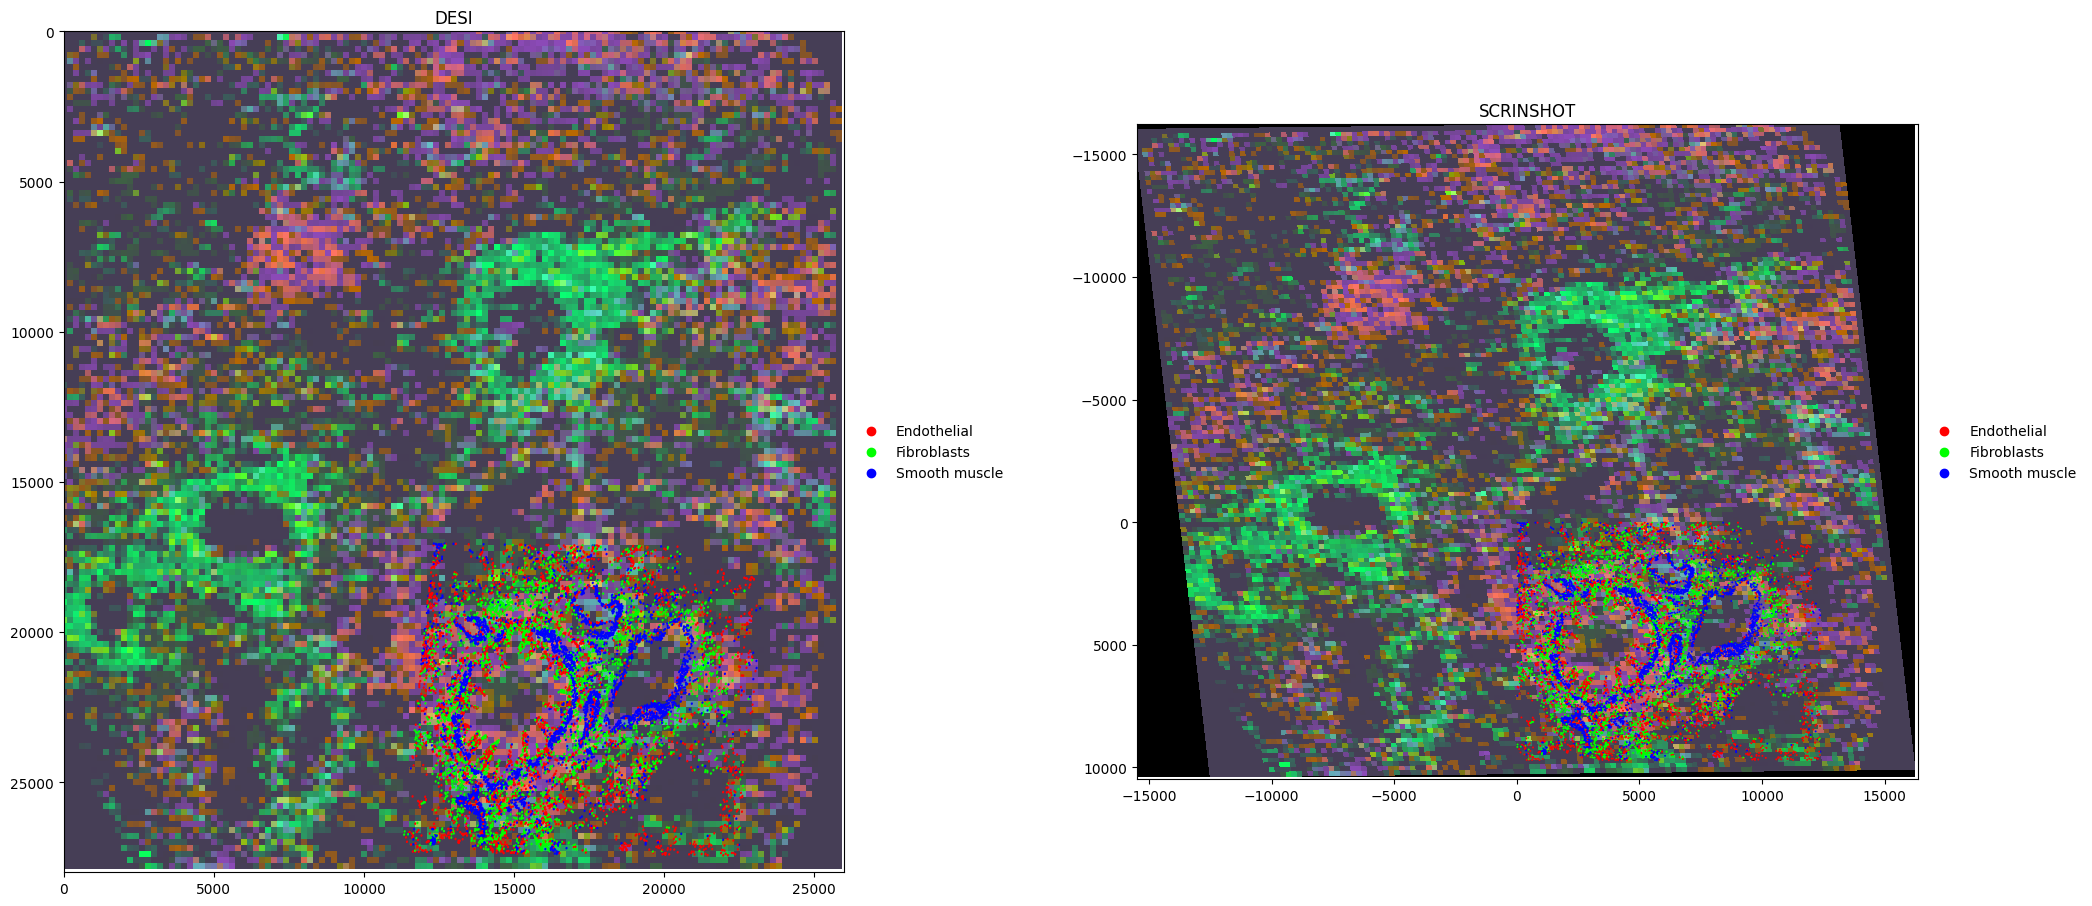

In [24]:
import spatialdata_plot
sdata["cell_types"].obs["Cell.type"] = sdata["cell_types"].obs["Cell.type"].astype("category")

sdata.pl.render_images("DESI_image").pl.render_shapes(
    "cells", 
    color="Cell.type", 
    groups=['Endothelial','Fibroblasts','Smooth muscle'], 
    palette=['#FF0000','#00FF00','#0000FF'], 
    method="matplotlib",
).pl.show()

Visualize in Napari:

In [15]:
i = Interactive(sdata)
i.run()

2025-02-17 15:35:37.373 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2025-02-17 15:35:37.374 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2025-02-17 15:35:42.951 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2025-02-17 15:35:42.964 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2025-02-17 15:35:42.998 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.


Export to TissUUmaps:

In [ ]:
# Get all coordinate systems:
coordinate_systems = sdata.coordinate_systems

output_folder = f"{output_folder}/tissuumaps/13Oct_P3_lung_DESI_SCRINSHOT_SUBSET"
os.makedirs(output_folder, exist_ok=True)

for cs in coordinate_systems:
    print(f"Converting to TissUUmaps in coordinate system: {cs}")
    sdata_extended, tmap_file = tissuumaps_helper.spatialdata_to_tissuumaps(
        sdata, 
        elements = {
            "images": ["DESI_image", "hyb1_DAPI"],
            "shapes": ["anatomical_labels", "cells-large"],
            "tables": ["DESI_obs", "cell_types"],
            "points": ["SCRINSHOT_DOT_COORDINATES"],
        },
        output_folder = output_folder,
        coordinate_system = cs
    )
    
    # Post-process the TissUUmaps file:
    with open(tmap_file, "r") as f:
        tmap_state = json.load(f)
    
    tmap_state["markerFiles"][0]["expectedHeader"]["scale_factor"] = 2
    tmap_state["markerFiles"][1]["expectedHeader"]["scale_factor"] = 0.4
    tmap_state["markerFiles"][2]["expectedHeader"]["scale_factor"] = 0.1
    for markerFile in tmap_state["markerFiles"]:
        for dropdownOption in markerFile["dropdownOptions"]:
            dropdownOption["name"] = dropdownOption["name"].replace("Gene expression: ", "")

    tmap_state["layers"][-1]["clip"] = {
        "x": float(sdata_extended["SCRINSHOT_DOT_COORDINATES"].x.compute().min()),
        "y": float(sdata_extended["SCRINSHOT_DOT_COORDINATES"].y.compute().min()),
        "w": float(sdata_extended["SCRINSHOT_DOT_COORDINATES"].x.compute().max() - sdata_extended["SCRINSHOT_DOT_COORDINATES"].x.compute().min()),
        "h": float(sdata_extended["SCRINSHOT_DOT_COORDINATES"].y.compute().max() - sdata_extended["SCRINSHOT_DOT_COORDINATES"].y.compute().min()),
    }
    
    with open(tmap_file, "w") as f:
        json.dump(tmap_state, f, indent=2)

Converting to TissUUmaps in coordinate system: DESI
  - Adding image DESI_image
  - Adding image hyb1_DAPI
  - Adding shape anatomical_labels
  - Adding shape cells-large
  - Adding table DESI_obs
  - Adding table cell_types
  - Adding points SCRINSHOT_DOT_COORDINATES
Converting to TissUUmaps in coordinate system: SCRINSHOT
  - Adding image DESI_image
  - Adding image hyb1_DAPI
  - Adding shape anatomical_labels
  - Adding shape cells-large
  - Adding table DESI_obs
  - Adding table cell_types
  - Adding points SCRINSHOT_DOT_COORDINATES


Save the SpatialData object to a zarr object on disk:

In [ ]:
# Save the updated spatialdata object:

output_path = f"{output_folder}/zarr/13Oct_P3_lung_DESI_SCRINSHOT_SUBSET.zarr"
print(output_path)
os.makedirs(os.path.dirname(output_path), exist_ok=True)
sdata.write(output_path, overwrite=True)

C:/Users/matsmi/OneDrive - Karolinska Institutet/Dokument/__STUDIES/008_DESI-SCRINSHOT_dev/results/output.zarr
INFO     The Zarr backing store has been changed from None the new file path: C:\Users\matsmi\OneDrive - Karolinska
         Institutet\Dokument\__STUDIES\008_DESI-SCRINSHOT_dev\results\output.zarr                                  
